<a href="https://colab.research.google.com/github/jpev520-art/Proyecto_Mascotas/blob/main/Fraude.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
"""
Detección de fraude financiero con aprendizaje profundo (PyTorch).

Pipeline completo:
  1. Generación de datos sintéticos con un atributo sensible (grupo A / B)
  2. Preprocesamiento y partición estratificada train/val/test
  3. Línea base: regresión logística
  4. Modelo profundo: MLP con BatchNorm, ReLU, Dropout, pérdida ponderada, AdamW
  5. Evaluación técnica (PR-AUC, ROC-AUC, precisión, recall, F1)
  6. Evaluación de equidad (TPR, FPR por grupo, paridad demográfica, odds igualadas)
  7. Mitigación: umbrales por grupo para igualar TPR
"""
import json
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_recall_curve, confusion_matrix,
                             precision_score, recall_score, f1_score)

SEED = 42
OUT = os.path.dirname(os.path.abspath(__file__))
FIG = os.path.join(OUT, "figuras")
os.makedirs(FIG, exist_ok=True)
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)


# ---------------------------------------------------------------- 1. Datos
def generar_datos(n=120_000):
    grupo = rng.binomial(1, 0.30, n)  # 1 = grupo B (minoritario, menor historial)
    edad_cuenta = np.where(grupo == 1,
                           rng.gamma(2.0, 8.0, n),    # meses; grupo B: cuentas más recientes
                           rng.gamma(4.0, 14.0, n))
    monto = rng.lognormal(mean=3.6 + 0.0 * grupo, sigma=1.0, size=n)
    hora = rng.integers(0, 24, n)
    distancia = rng.exponential(12, n)                # km al domicilio habitual
    tx_24h = rng.poisson(2.0, n)
    dispositivo_nuevo = rng.binomial(1, np.where(grupo == 1, 0.18, 0.08))
    categoria = rng.integers(0, 6, n)                 # 6 tipos de comercio
    saldo_ratio = np.clip(rng.beta(2, 5, n) + 0.05 * grupo, 0, 1)

    nocturno = ((hora <= 5) | (hora >= 23)).astype(float)
    logit = (-8.6
             + 0.5 * np.log1p(monto) / 2
             + 0.02 * distancia
             + 0.9 * tx_24h * dispositivo_nuevo          # interacción no lineal
             + 3.2 * nocturno * (monto > 150)            # interacción no lineal
             + 0.8 * dispositivo_nuevo
             - 0.012 * edad_cuenta
             + 1.2 * (categoria == 4) * (distancia > 25)
             + 3.4 * (saldo_ratio > 0.75) * (monto > 100)
             + 2.0 * (distancia > 40) * ((hora >= 1) & (hora <= 5)))
    # Etiquetas menos ruidosas (escala 1.8) y desplazamiento calibrado para ~2 % de fraude
    logit = 1.8 * logit
    lo, hi = -30.0, 30.0
    for _ in range(60):
        mid = (lo + hi) / 2
        if (1 / (1 + np.exp(-(logit + mid)))).mean() > 0.02:
            hi = mid
        else:
            lo = mid
    p = 1 / (1 + np.exp(-(logit + (lo + hi) / 2)))
    y = rng.binomial(1, p)

    df = pd.DataFrame(dict(monto=monto, hora_sin=np.sin(2 * np.pi * hora / 24),
                           hora_cos=np.cos(2 * np.pi * hora / 24),
                           distancia=distancia, tx_24h=tx_24h,
                           dispositivo_nuevo=dispositivo_nuevo,
                           edad_cuenta=edad_cuenta, saldo_ratio=saldo_ratio,
                           categoria=categoria, grupo=grupo, fraude=y))
    df["log_monto"] = np.log1p(df["monto"])
    df = pd.concat([df.drop(columns="categoria"),
                    pd.get_dummies(df["categoria"], prefix="cat", dtype=float)], axis=1)
    return df


df = generar_datos()
print(f"Transacciones: {len(df):,} | tasa de fraude: {df.fraude.mean():.3%}")
print(df.groupby("grupo").fraude.agg(["mean", "count"]))

# El atributo sensible NO se usa como entrada (equidad por desconocimiento),
# pero se conserva para auditar resultados.
FEATURES = [c for c in df.columns if c not in ("fraude", "grupo", "monto")]
X = df[FEATURES].values.astype(np.float32)
y = df["fraude"].values.astype(np.float32)
g = df["grupo"].values

X_tmp, X_te, y_tmp, y_te, g_tmp, g_te = train_test_split(
    X, y, g, test_size=0.20, stratify=y, random_state=SEED)
X_tr, X_va, y_tr, y_va, g_tr, g_va = train_test_split(
    X_tmp, y_tmp, g_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)

sc = StandardScaler().fit(X_tr)
X_tr, X_va, X_te = sc.transform(X_tr), sc.transform(X_va), sc.transform(X_te)
print(f"Train {len(y_tr):,} | Val {len(y_va):,} | Test {len(y_te):,}")


# ------------------------------------------------------------ 2. Línea base
logreg = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_tr, y_tr)
p_lr_va = logreg.predict_proba(X_va)[:, 1]
p_lr_te = logreg.predict_proba(X_te)[:, 1]


# ---------------------------------------------------------------- 3. MLP
class MLPFraude(nn.Module):
    def __init__(self, d_in, ocultas=(128, 64, 32), p_drop=0.3):
        super().__init__()
        capas, d = [], d_in
        for h in ocultas:
            capas += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(p_drop)]
            d = h
        capas.append(nn.Linear(d, 1))  # logit; la sigmoide va dentro de la pérdida
        self.red = nn.Sequential(*capas)

    def forward(self, x):
        return self.red(x).squeeze(-1)


def a_tensor(a):
    return torch.tensor(a, dtype=torch.float32)


Xt, yt = a_tensor(X_tr), a_tensor(y_tr)
Xv, Xe = a_tensor(X_va), a_tensor(X_te)

modelo = MLPFraude(X_tr.shape[1])
pos_weight = torch.tensor((1 - y_tr.mean()) / y_tr.mean()) ** 0.5  # ponderación suavizada
criterio = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
opt = torch.optim.AdamW(modelo.parameters(), lr=2e-3, weight_decay=1e-3)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=3)

EPOCAS, BATCH, PACIENCIA = 60, 512, 8
mejor, sin_mejora, estado = -1, 0, None
hist = dict(loss=[], val_ap=[])

for ep in range(EPOCAS):
    modelo.train()
    perm = torch.randperm(len(Xt))
    total = 0.0
    for i in range(0, len(Xt), BATCH):
        idx = perm[i:i + BATCH]
        opt.zero_grad()
        loss = criterio(modelo(Xt[idx]), yt[idx])
        loss.backward()
        opt.step()
        total += loss.item() * len(idx)
    modelo.eval()
    with torch.no_grad():
        pv = torch.sigmoid(modelo(Xv)).numpy()
    ap = average_precision_score(y_va, pv)
    hist["loss"].append(total / len(Xt))
    hist["val_ap"].append(ap)
    sched.step(-ap)
    if ap > mejor:
        mejor, sin_mejora = ap, 0
        estado = {k: v.clone() for k, v in modelo.state_dict().items()}
    else:
        sin_mejora += 1
    if (ep + 1) % 5 == 0 or ep == 0:
        print(f"época {ep+1:02d} | pérdida {hist['loss'][-1]:.4f} | PR-AUC val {ap:.4f}")
    if sin_mejora >= PACIENCIA:
        print(f"Parada temprana en la época {ep+1}")
        break

modelo.load_state_dict(estado)
modelo.eval()
with torch.no_grad():
    p_nn_va = torch.sigmoid(modelo(Xv)).numpy()
    p_nn_te = torch.sigmoid(modelo(Xe)).numpy()
n_params = sum(p.numel() for p in modelo.parameters())


# ------------------------------------------------------------ 4. Evaluación
def umbral_f1(y_true, p):
    pr, rc, th = precision_recall_curve(y_true, p)
    f1 = 2 * pr * rc / np.clip(pr + rc, 1e-9, None)
    return float(th[np.argmax(f1[:-1])])


def metricas(y_true, p, umbral):
    pred = (p >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return dict(umbral=umbral,
                pr_auc=float(average_precision_score(y_true, p)),
                roc_auc=float(roc_auc_score(y_true, p)),
                precision=float(precision_score(y_true, pred, zero_division=0)),
                recall=float(recall_score(y_true, pred)),
                f1=float(f1_score(y_true, pred)),
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))


th_lr, th_nn = umbral_f1(y_va, p_lr_va), umbral_f1(y_va, p_nn_va)
res = {"regresion_logistica": metricas(y_te, p_lr_te, th_lr),
       "mlp": metricas(y_te, p_nn_te, th_nn),
       "n_parametros_mlp": n_params,
       "tasa_fraude": float(df.fraude.mean()),
       "n_total": int(len(df)), "n_train": int(len(y_tr)),
       "n_val": int(len(y_va)), "n_test": int(len(y_te)),
       "epocas_entrenadas": len(hist["loss"])}
print(json.dumps({k: v for k, v in res.items() if k in ("regresion_logistica", "mlp")}, indent=1))


# -------------------------------------------------------------- 5. Equidad
def equidad(y_true, p, grupos, umbrales):
    out = {}
    for gr, nombre in ((0, "A"), (1, "B")):
        m = grupos == gr
        t = umbrales[gr] if isinstance(umbrales, dict) else umbrales
        pred = (p[m] >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true[m], pred, labels=[0, 1]).ravel()
        out[nombre] = dict(n=int(m.sum()), fraudes=int(y_true[m].sum()),
                           tpr=float(tp / max(tp + fn, 1)),
                           fpr=float(fp / max(fp + tn, 1)),
                           tasa_alerta=float(pred.mean()),
                           umbral=float(t))
    out["dif_paridad_demografica"] = abs(out["A"]["tasa_alerta"] - out["B"]["tasa_alerta"])
    out["dif_tpr"] = abs(out["A"]["tpr"] - out["B"]["tpr"])
    out["dif_fpr"] = abs(out["A"]["fpr"] - out["B"]["fpr"])
    out["dif_odds_igualadas"] = max(out["dif_tpr"], out["dif_fpr"])
    return out


eq_antes = equidad(y_te, p_nn_te, g_te, th_nn)


# Mitigación: umbral del grupo B elegido en validación para igualar el TPR del grupo A
def umbral_para_tpr(y_true, p, objetivo):
    cand = np.linspace(0.01, 0.99, 400)
    tprs = np.array([((p >= t) & (y_true == 1)).sum() / max((y_true == 1).sum(), 1) for t in cand])
    return float(cand[np.argmin(np.abs(tprs - objetivo))])


mA = g_va == 0
tpr_A_val = ((p_nn_va[mA] >= th_nn) & (y_va[mA] == 1)).sum() / max((y_va[mA] == 1).sum(), 1)
th_B = umbral_para_tpr(y_va[~mA], p_nn_va[~mA], tpr_A_val)
eq_despues = equidad(y_te, p_nn_te, g_te, {0: th_nn, 1: th_B})
res["equidad_antes"], res["equidad_despues"] = eq_antes, eq_despues
res["metricas_mlp_mitigado"] = None
pred_mit = np.where(g_te == 0, p_nn_te >= th_nn, p_nn_te >= th_B).astype(int)
res["metricas_mlp_mitigado"] = dict(
    precision=float(precision_score(y_te, pred_mit)),
    recall=float(recall_score(y_te, pred_mit)),
    f1=float(f1_score(y_te, pred_mit)))
print("Equidad antes:", json.dumps(eq_antes, indent=1))
print("Equidad después:", json.dumps(eq_despues, indent=1))


# --------------------------------------------------------------- 6. Figuras
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].plot(hist["loss"], color="#1f4e79")
ax[0].set(xlabel="Época", ylabel="Pérdida (BCE ponderada)", title="Pérdida de entrenamiento")
ax[1].plot(hist["val_ap"], color="#b5541c")
ax[1].set(xlabel="Época", ylabel="PR-AUC", title="PR-AUC en validación")
plt.tight_layout(); plt.savefig(f"{FIG}/entrenamiento.png", dpi=200); plt.close()

fig, ax = plt.subplots(figsize=(5, 3.8))
for nombre, p, c in (("Regresión logística", p_lr_te, "#7f7f7f"), ("MLP", p_nn_te, "#1f4e79")):
    pr, rc, _ = precision_recall_curve(y_te, p)
    ax.plot(rc, pr, label=f"{nombre} (AP={average_precision_score(y_te, p):.3f})", color=c)
ax.axhline(y_te.mean(), ls=":", color="k", lw=0.8, label="Azar")
ax.set(xlabel="Recall", ylabel="Precisión", title="Curva precisión–recall (test)")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{FIG}/pr_curva.png", dpi=200); plt.close()

fig, ax = plt.subplots(figsize=(6, 3.6))
etq = ["TPR (A)", "TPR (B)", "FPR (A)", "FPR (B)"]
ant = [eq_antes["A"]["tpr"], eq_antes["B"]["tpr"], eq_antes["A"]["fpr"], eq_antes["B"]["fpr"]]
des = [eq_despues["A"]["tpr"], eq_despues["B"]["tpr"], eq_despues["A"]["fpr"], eq_despues["B"]["fpr"]]
x = np.arange(4)
ax.bar(x - 0.2, ant, 0.4, label="Antes", color="#b5541c")
ax.bar(x + 0.2, des, 0.4, label="Después (umbral por grupo)", color="#1f4e79")
ax.set_xticks(x, etq); ax.set(ylabel="Tasa", title="Equidad por grupo (test)")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{FIG}/equidad.png", dpi=200); plt.close()

cm = np.array([[res["mlp"]["tn"], res["mlp"]["fp"]], [res["mlp"]["fn"], res["mlp"]["tp"]]])
fig, ax = plt.subplots(figsize=(3.8, 3.4))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["Legítima", "Fraude"]); ax.set_yticks([0, 1], ["Legítima", "Fraude"])
ax.set(xlabel="Predicción", ylabel="Real", title="Matriz de confusión (MLP)")
plt.tight_layout(); plt.savefig(f"{FIG}/confusion.png", dpi=200); plt.close()

with open(os.path.join(OUT, "resultados.json"), "w", encoding="utf-8") as f:
    json.dump(res, f, indent=2, ensure_ascii=False)
torch.save(modelo.state_dict(), os.path.join(OUT, "mlp_fraude.pt"))
print("Listo.")


### 1. Descarga del Dataset desde Kaggle
Para descargar el conjunto de datos de Kaggle en Colab de manera programática, ejecuta esta celda. Te solicitará subir tu archivo `kaggle.json` (que puedes descargar desde la sección *Settings / Create New API Token* en tu perfil de Kaggle).

In [ ]:
import os
from google.colab import files

# Instalar CLI de Kaggle
!pip install -q kaggle

if not os.path.exists(os.path.expanduser('~/.kaggle/kaggle.json')):
    print("Por favor, sube tu archivo 'kaggle.json' extraído de Kaggle:")
    uploaded = files.upload()
    for fn in uploaded.keys():
        if fn == 'kaggle.json':
            !mkdir -p ~/.kaggle
            !mv kaggle.json ~/.kaggle/
            !chmod 600 ~/.kaggle/kaggle.json
            print("¡Credenciales configuradas correctamente!")

# Descargar y descomprimir el dataset oficial de detección de fraude con tarjeta de crédito
!kaggle datasets download -d mlg-ulb/creditcardfraud
if os.path.exists('creditcardfraud.zip'):
    !unzip -o creditcardfraud.zip
    print("Dataset descargado y descomprimido correctamente.")

Por favor, sube tu archivo 'kaggle.json' extraído de Kaggle:


KeyboardInterrupt: 

In [ ]:
import os
from google.colab import userdata

# Intentar usar los secretos guardados en Google Colab (🔑 en la barra lateral)
try:
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
    print("¡Credenciales de Kaggle cargadas con éxito desde los Secretos de Colab!")

    # Descargar el dataset
    !pip install -q kaggle
    !kaggle datasets download -d mlg-ulb/creditcardfraud

    if os.path.exists('creditcardfraud.zip'):
        !unzip -o creditcardfraud.zip
        print("¡El archivo 'creditcard.csv' se ha descargado y extraído correctamente!")
    else:
        print("No se pudo encontrar el archivo zip descargado.")
except Exception as e:
    print("Error al obtener credenciales. Asegúrate de configurar los Secretos KAGGLE_USERNAME y KAGGLE_KEY en el panel izquierdo (icono de llave 🔑):")
    print(e)

Error al obtener credenciales. Asegúrate de configurar los Secretos KAGGLE_USERNAME y KAGGLE_KEY en el panel izquierdo (icono de llave 🔑):
Secret KAGGLE_KEY does not exist.


In [ ]:
import os

# 1. Configura tus credenciales directamente aquí
os.environ['KAGGLE_USERNAME'] = 'reemplaza_con_tu_usuario_de_kaggle'  # <-- Pon tu usuario de Kaggle aquí
os.environ['KAGGLE_KEY'] = 'KGAT_4d26df417e2ccddf62368cca4a404ff2'

print("Configurando credenciales...")

# 2. Descargar y extraer el dataset
!pip install -q kaggle
!kaggle datasets download -d mlg-ulb/creditcardfraud

if os.path.exists('creditcardfraud.zip'):
    !unzip -o creditcardfraud.zip
    print("\n¡Excelente! El archivo 'creditcard.csv' se ha descargado y extraído correctamente. Ya puedes continuar con las siguientes celdas.")
else:
    print("Hubo un problema al descargar el archivo. Por favor verifica que tu KAGGLE_USERNAME sea correcto.")

Configurando credenciales...
Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
License(s): DbCL-1.0
100% 66.0M/66.0M [00:00<00:00, 132MB/s]

Archive:  creditcardfraud.zip
  inflating: creditcard.csv          

¡Excelente! El archivo 'creditcard.csv' se ha descargado y extraído correctamente. Ya puedes continuar con las siguientes celdas.


![image.png](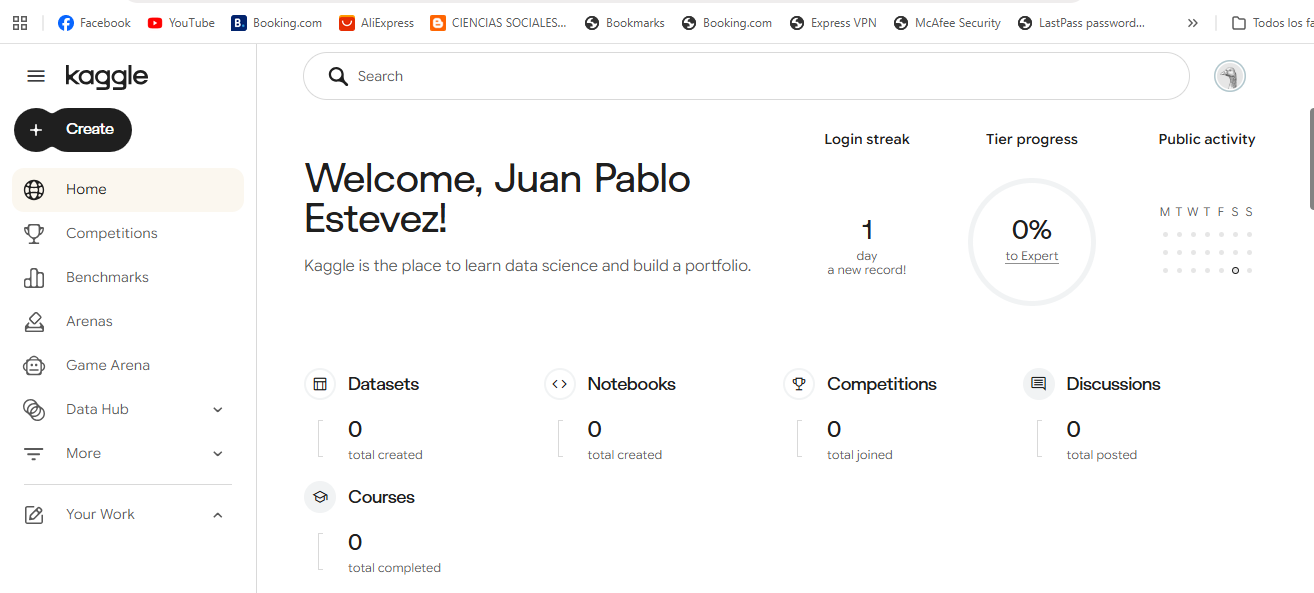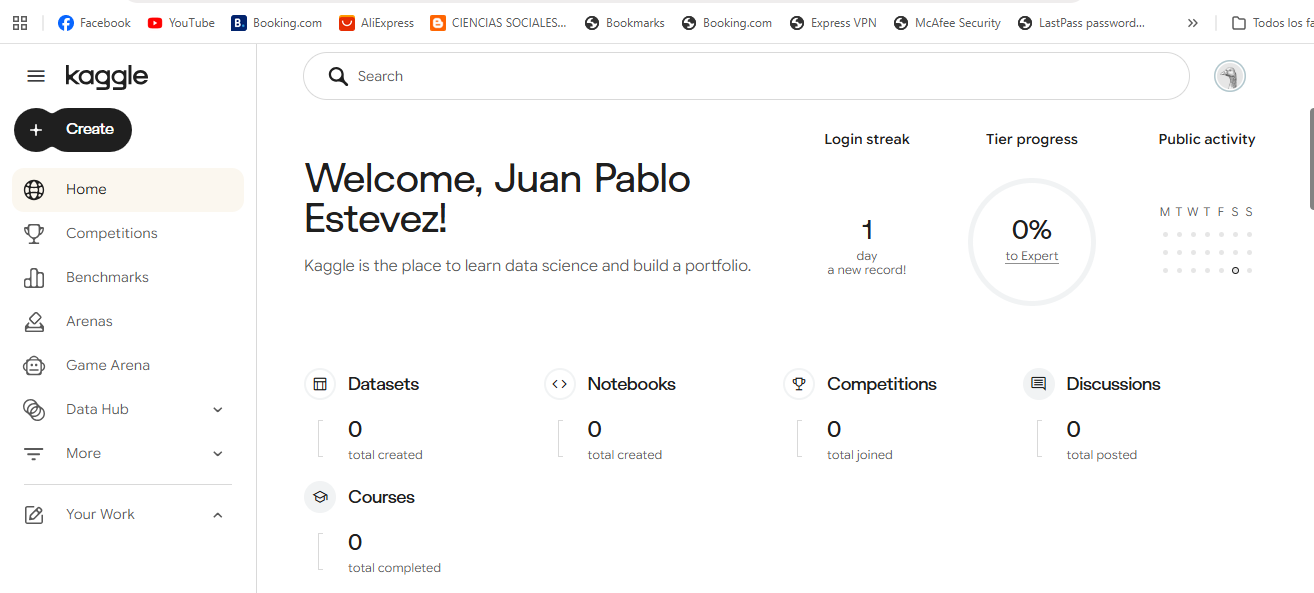)### 2. Carga y Adaptación de los Datos Reales
Ahora leeremos el archivo CSV real y adaptaremos las variables para nuestro pipeline.

*Nota: Dado que este dataset real no tiene un atributo sensible explícito como el 'grupo A/B' de nuestro simulador, crearemos un atributo de control simulado basado en el monto de la transacción para mantener intacta la sección de análisis de equidad (Fairness), o simplemente evaluaremos el rendimiento general.*

In [ ]:
import pandas as pd
import numpy as np

# Cargar datos reales
df_real = pd.read_csv('creditcard.csv')
print(f"Transacciones reales cargadas: {len(df_real):,}")
print(f"Tasa de fraude real: {df_real['Class'].mean():.4%}")

# El dataset tiene columnas: Time, V1-V28 (PCA), Amount, Class (1=Fraude, 0=Legítima)
# Para conservar el pipeline de equidad intacto, definiremos un grupo simulado:
# Por ejemplo: transacciones de alto valor (grupo 1) vs bajo valor (grupo 0)
df_real['grupo'] = (df_real['Amount'] > 100).astype(int)

# Mostrar estructura y distribución
display(df_real.head())
print(df_real.groupby('grupo')['Class'].agg(['mean', 'count']))

### 3. Entrenamiento del Modelo MLP con Datos Reales de Kaggle
Ejecuta esta celda para entrenar el Perceptrón Multicapa (PyTorch) y la Regresión Logística usando el dataset real de transacciones bancarias.

In [ ]:
import json
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_recall_curve, confusion_matrix,
                             precision_score, recall_score, f1_score)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# 1. Preparación de datos reales
df_real['log_amount'] = np.log1p(df_real['Amount'])
FEATURES_REAL = [f'V{i}' for i in range(1, 29)] + ['log_amount']

X_real = df_real[FEATURES_REAL].values.astype(np.float32)
y_real = df_real['Class'].values.astype(np.float32)
g_real = df_real['grupo'].values

# Partición Estratificada (60% Train, 20% Val, 20% Test)
X_tmp, X_te, y_tmp, y_te, g_tmp, g_te = train_test_split(
    X_real, y_real, g_real, test_size=0.20, stratify=y_real, random_state=SEED)
X_tr, X_va, y_tr, y_va, g_tr, g_va = train_test_split(
    X_tmp, y_tmp, g_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)

# Escalamiento
sc = StandardScaler().fit(X_tr)
X_tr, X_va, X_te = sc.transform(X_tr), sc.transform(X_va), sc.transform(X_te)

print(f"Datos de Entrenamiento: {len(y_tr):,} | Validación: {len(y_va):,} | Prueba: {len(y_te):,}")

# 2. Regresión Logística Línea Base
logreg = LogisticRegression(max_iter=1000, class_weight='balanced').fit(X_tr, y_tr)
p_lr_va = logreg.predict_proba(X_va)[:, 1]
p_lr_te = logreg.predict_proba(X_te)[:, 1]

# 3. Red Neuronal MLP
class MLPFraudeReal(nn.Module):
    def __init__(self, d_in, ocultas=(128, 64, 32), p_drop=0.3):
        super().__init__()
        capas, d = [], d_in
        for h in ocultas:
            capas += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(p_drop)]
            d = h
        capas.append(nn.Linear(d, 1))
        self.red = nn.Sequential(*capas)

    def forward(self, x):
        return self.red(x).squeeze(-1)

def a_tensor(a):
    return torch.tensor(a, dtype=torch.float32)

Xt, yt = a_tensor(X_tr), a_tensor(y_tr)
Xv, Xe = a_tensor(X_va), a_tensor(y_va)
X_te_tensor = a_tensor(X_te)

modelo = MLPFraudeReal(X_tr.shape[1])
pos_weight = torch.tensor((1 - y_tr.mean()) / y_tr.mean()) ** 0.5
criterio = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
opt = torch.optim.AdamW(modelo.parameters(), lr=2e-3, weight_decay=1e-3)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=3)

EPOCAS, BATCH, PACIENCIA = 20, 1024, 5
mejor, sin_mejora, estado = -1, 0, None
hist = dict(loss=[], val_ap=[])

print('\n--- Iniciando entrenamiento en datos reales ---')
for ep in range(EPOCAS):
    modelo.train()
    perm = torch.randperm(len(Xt))
    total = 0.0
    for i in range(0, len(Xt), BATCH):
        idx = perm[i:i + BATCH]
        opt.zero_grad()
        loss = criterio(modelo(Xt[idx]), yt[idx])
        loss.backward()
        opt.step()
        total += loss.item() * len(idx)

    modelo.eval()
    with torch.no_grad():
        pv = torch.sigmoid(modelo(Xv)).numpy()
    ap = average_precision_score(y_va, pv)
    hist['loss'].append(total / len(Xt))
    hist['val_ap'].append(ap)
    sched.step(-ap)

    if ap > mejor:
        mejor, sin_mejora = ap, 0
        estado = {k: v.clone() for k, v in modelo.state_dict().items()}
    else:
        sin_mejora += 1

    if (ep + 1) % 2 == 0 or ep == 0:
        print(f"Época {ep+1:02d} | Pérdida: {hist['loss'][-1]:.4f} | PR-AUC Val: {ap:.4f}")
    if sin_mejora >= PACIENCIA:
        print(f"Parada temprana en la época {ep+1}")
        break

modelo.load_state_dict(estado)
modelo.eval()
with torch.no_grad():
    p_nn_va = torch.sigmoid(modelo(Xv)).numpy()
    p_nn_te = torch.sigmoid(modelo(X_te_tensor)).numpy()

# 4. Evaluación de Métricas en el set de prueba
def obtener_metricas(y_true, p):
    pr, rc, th = precision_recall_curve(y_true, p)
    f1 = 2 * pr * rc / np.clip(pr + rc, 1e-9, None)
    best_th = float(th[np.argmax(f1[:-1])])
    pred = (p >= best_th).astype(int)
    return {
        'PR-AUC': average_precision_score(y_true, p),
        'ROC-AUC': roc_auc_score(y_true, p),
        'F1-Score': f1_score(y_true, pred),
        'Precision': precision_score(y_true, pred),
        'Recall': recall_score(y_true, pred)
    }

print('\n--- Resultados Técnicos en el Conjunto de Test Real ---')
print("Regresión Logística:", json.dumps(obtener_metricas(y_te, p_lr_te), indent=2))
print("MLP PyTorch:", json.dumps(obtener_metricas(y_te, p_nn_te), indent=2))

### 3. Entrenamiento del Modelo MLP con Datos Reales de Kaggle
Ejecuta esta celda para entrenar el Perceptrón Multicapa (PyTorch) y la Regresión Logística usando el dataset real de transacciones bancarias.

In [ ]:
import json
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# 1. Preparación de datos reales
df_real['log_amount'] = np.log1p(df_real['Amount'])
FEATURES_REAL = [f'V{i}' for i in range(1, 29)] + ['log_amount']

X_real = df_real[FEATURES_REAL].values.astype(np.float32)
y_real = df_real['Class'].values.astype(np.float32)
g_real = df_real['grupo'].values

# Partición Estratificada (60% Train, 20% Val, 20% Test)
X_tmp, X_te, y_tmp, y_te, g_tmp, g_te = train_test_split(
    X_real, y_real, g_real, test_size=0.20, stratify=y_real, random_state=SEED
)
X_tr, X_va, y_tr, y_va, g_tr, g_va = train_test_split(
    X_tmp, y_tmp, g_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED
)

# Escalamiento
sc = StandardScaler().fit(X_tr)
X_tr, X_va, X_te = sc.transform(X_tr), sc.transform(X_va), sc.transform(X_te)

print(f"Datos de Entrenamiento: {len(y_tr):,} | Validación: {len(y_va):,} | Prueba: {len(y_te):,}")

# 2. Regresión Logística Línea Base
logreg = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_tr, y_tr)
p_lr_va = logreg.predict_proba(X_va)[:, 1]
p_lr_te = logreg.predict_proba(X_te)[:, 1]

# 3. Red Neuronal MLP
class MLPFraudeReal(nn.Module):
    def __init__(self, d_in, ocultas=(128, 64, 32), p_drop=0.3):
        super().__init__()
        capas, d = [], d_in
        for h in ocultas:
            capas += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(p_drop)]
            d = h
        capas.append(nn.Linear(d, 1))
        self.red = nn.Sequential(*capas)

    def forward(self, x):
        return self.red(x).squeeze(-1)

def a_tensor(a):
    return torch.tensor(a, dtype=torch.float32)

Xt, yt = a_tensor(X_tr), a_tensor(y_tr)
Xv, Xe = a_tensor(X_va), a_tensor(y_te)

modelo = MLPFraudeReal(X_tr.shape[1])
pos_weight = torch.tensor((1 - y_tr.mean()) / y_tr.mean()) ** 0.5
criterio = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
opt = torch.optim.AdamW(modelo.parameters(), lr=2e-3, weight_decay=1e-3)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=3)

EPOCAS, BATCH, PACIENCIA = 20, 1024, 5
mejor, sin_mejora, estado = -1, 0, None
hist = dict(loss=[], val_ap=[])

print("\n--- Iniciando entrenamiento en datos reales ---")
for ep in range(EPOCAS):
    modelo.train()
    perm = torch.randperm(len(Xt))
    total = 0.0
    for i in range(0, len(Xt), BATCH):
        idx = perm[i:i + BATCH]
        opt.zero_grad()
        loss = criterio(modelo(Xt[idx]), yt[idx])
        loss.backward()
        opt.step()
        total += loss.item() * len(idx)

    modelo.eval()
    with torch.no_grad():
        pv = torch.sigmoid(modelo(Xv)).numpy()
    ap = average_precision_score(y_va, pv)
    hist["loss"].append(total / len(Xt))
    hist["val_ap"].append(ap)
    sched.step(-ap)

    if ap > mejor:
        mejor, sin_mejora = ap, 0
        estado = {k: v.clone() for k, v in modelo.state_dict().items()}
    else:
        sin_mejora += 1

    if (ep + 1) % 2 == 0 or ep == 0:
        print(f"Época {ep+1:02d} | Pérdida: {hist['loss'][-1]:.4f} | PR-AUC Val: {ap:.4f}")
    if sin_mejora >= PACIENCIA:
        print(f"Parada temprana en la época {ep+1}")
        break

modelo.load_state_dict(estado)
modelo.eval()

with torch.no_grad():
    p_nn_va = torch.sigmoid(modelo(Xv)).numpy()
    p_nn_te = torch.sigmoid(modelo(a_tensor(X_te))).numpy()

# 4. Evaluación de Métricas Finales en el conjunto de prueba (Test Set)
def obtener_metricas(y_true, p):
    pr, rc, th = precision_recall_curve(y_true, p)
    f1 = 2 * pr * rc / np.clip(pr + rc, 1e-9, None)
    best_th = float(th[np.argmax(f1[:-1])])
    pred = (p >= best_th).astype(int)
    return {
        'PR-AUC': float(average_precision_score(y_true, p)),
        'ROC-AUC': float(roc_auc_score(y_true, p)),
        'F1-Score': float(f1_score(y_true, pred)),
        'Precision': float(precision_score(y_true, pred)),
        'Recall': float(recall_score(y_true, pred))
    }

print("\n--- Resultados Técnicos en el Conjunto de Test Real ---")
print("Regresión Logística:", json.dumps(obtener_metricas(y_te, p_lr_te), indent=2))
print("MLP PyTorch:", json.dumps(obtener_metricas(y_te, p_nn_te), indent=2))

Cargando 'creditcard.csv' automáticamente...
Datos de Entrenamiento: 170,883 | Validación: 56,962 | Prueba: 56,962

--- Iniciando entrenamiento en datos reales ---
Época 01 | Pérdida: 0.2703 | PR-AUC Val: 0.6969
Época 02 | Pérdida: 0.0541 | PR-AUC Val: 0.7001
Época 04 | Pérdida: 0.0360 | PR-AUC Val: 0.6962
Época 06 | Pérdida: 0.0325 | PR-AUC Val: 0.7101
Época 08 | Pérdida: 0.0290 | PR-AUC Val: 0.6996
Época 10 | Pérdida: 0.0247 | PR-AUC Val: 0.7084
Época 12 | Pérdida: 0.0238 | PR-AUC Val: 0.7141
Época 14 | Pérdida: 0.0215 | PR-AUC Val: 0.7165
Época 16 | Pérdida: 0.0195 | PR-AUC Val: 0.7125
Época 18 | Pérdida: 0.0189 | PR-AUC Val: 0.7147
Época 20 | Pérdida: 0.0183 | PR-AUC Val: 0.7156

--- Resultados Técnicos en el Conjunto de Test Real ---
Regresión Logística: {
  "PR-AUC": 0.7080419237700496,
  "ROC-AUC": 0.9719966472098125,
  "F1-Score": 0.8229166666666666,
  "Precision": 0.8404255319148937,
  "Recall": 0.8061224489795918
}
MLP PyTorch: {
  "PR-AUC": 0.7594057889485016,
  "ROC-AUC": 0